In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
# import netCDF4 as nc
import os

import matplotlib as mpl

def moving_avg(temps,N=20):
    moving_avg = np.cumsum(temps)
    moving_avg[N:] -= moving_avg[:-N]
    moving_avg[N:] /= N
    moving_avg[:N] /= np.arange(1,N+1)
    return moving_avg

def PA_compliant(temps):
    if np.max(temps) > 2:
        return False
    elif np.mean(temps[-20:]) <= 1.5:
        return True
    else:
        return False

def OS_ref(temps,ref=1.5,window=1):
    stat_yrs = np.where(np.abs(df[s].to_numpy()-ref)<=0.05)[0]
    if len(stat_yrs) < 2:
        return False
    elif np.diff(stat_yrs).max()>window:
        return True
    else:
        return False 
    return 

# Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

https://zenodo.org/records/11108741 for actual data set

In [2]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

/tmp/ipykernel_28887/3192702059.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_28887/3192702059.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


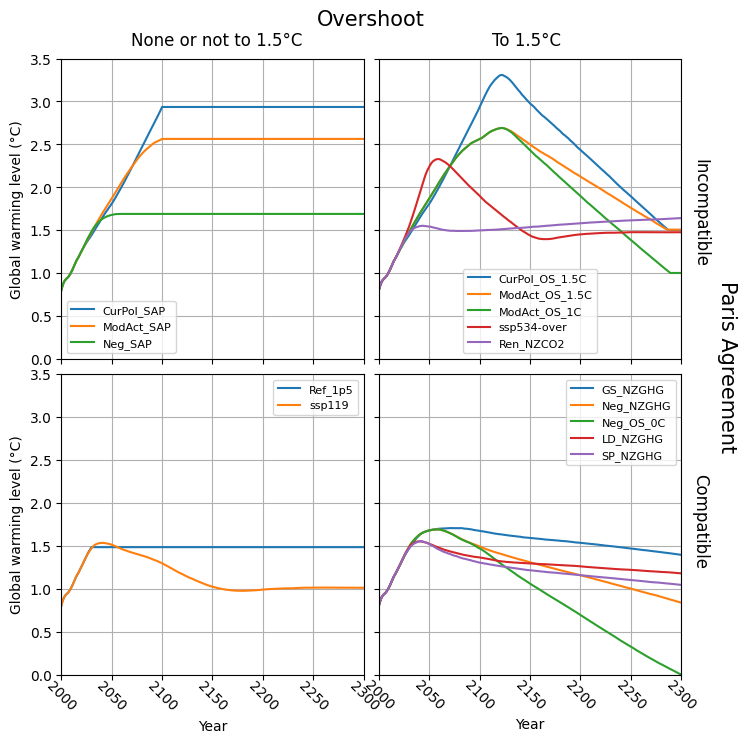

In [3]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
axs[0,0].set_ylim(0,3.5)
for s in scenarios:
    # if PA_compliant(temps = df[s]):
    #     col = 'green'
    # else:
    #     col = 'red'
    # if OS_ref(df[s].to_numpy()):
    #     ls='-'
    # else: 
    #     ls = '--'
    temp=df[s].to_numpy()
    axs[int(PA_compliant(temp)), int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), df[s], label=s)

for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Global warming level (°C)')

# axs[1,0].tick_params(axis='x',labelrotation=+45)
axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['None or not to 1.5°C', 'To 1.5°C'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")
# fig.tight_layout()
# axs[1,0].set_xticks([2000,2050,2100,2150,2200,2250])

# Simulations with Armstrong Mckay thresholds

In [8]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='Sheet1')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [9]:
# -------- SIMULATIONS --------------
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df[s].to_numpy()[t], T_lim, betas))

In [10]:
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in tqdm.tqdm(range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

100%|██████████████████████████████████████| 450/450 [00:00<00:00, 10417.58it/s]


In [12]:
D.shape

(15, 500, 9, 451)

In [23]:
D_sos = (D>0.1).sum(axis=-2)

In [41]:
print(data.shape)

(15, 9, 451)


/tmp/ipykernel_90909/762252096.py:19: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/tmp/ipykernel_90909/762252096.py:21: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



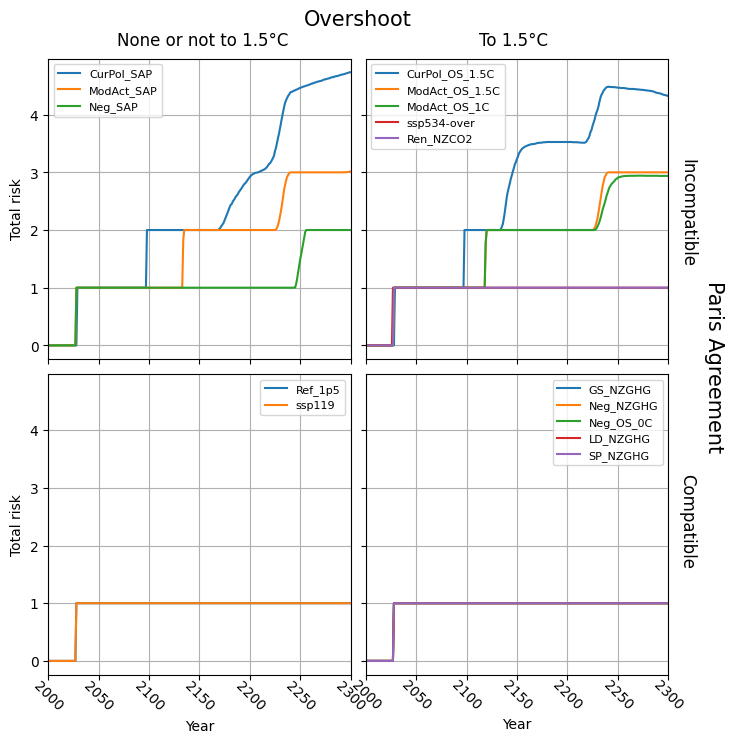

In [192]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,3.5)
data = (D>0.1).mean(axis=1).sum(axis=1)
# j=7
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        data[i,:], label=s)
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Total risk')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")

fig.savefig('../../Figures/Overshoots/PROVIDE/Risk_with_AM22.png',bbox_inches='tight')

In [25]:
TEs

array(['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS',
       'WAM'], dtype=object)

C:\Users\baraj\AppData\Local\Temp\ipykernel_22856\126150043.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
C:\Users\baraj\AppData\Local\Temp\ipykernel_22856\126150043.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


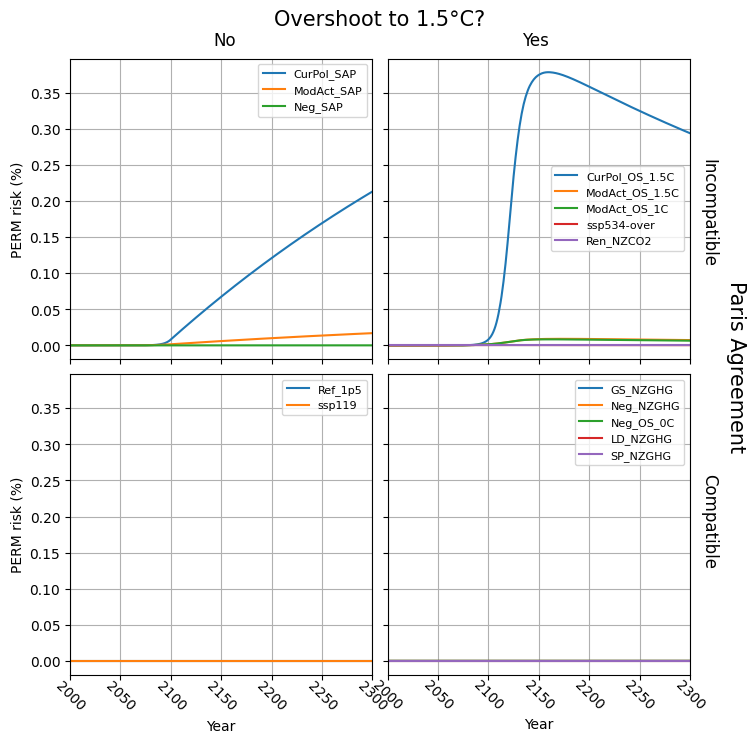

In [27]:
TE= 'PERM'
TEs=df_TEs.index.values
te_ind = np.where(TEs==TE)[0][0]
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,3.5)
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        D[i,:,te_ind,:].mean(axis=0)*100, label=s)
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel(TE+' risk (%)')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")

In [44]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

In [50]:
data.shape

(15, 9, 451)

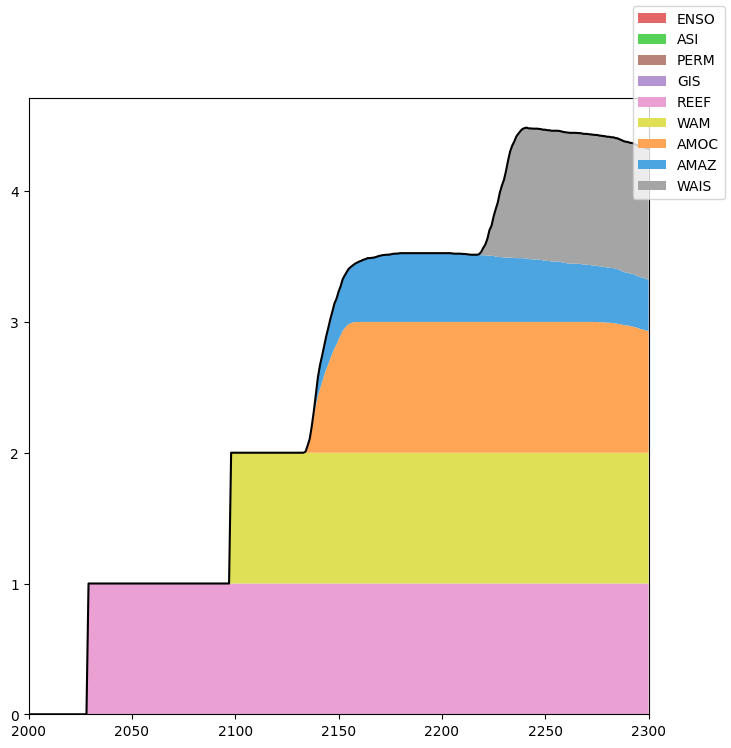

In [70]:
fig,ax=plt.subplots(figsize=(8,8))
# plt.subplots_adjust(wspace=0.05,hspace=0.05)
ax.set_xlim(2000,2300)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# axs[0,0].set_ylim(0,3.5)
data = (D>0.1).mean(axis=1)
# j=7
# for i,s in enumerate(scenarios):
s='CurPol_OS_1.5C'
i=1
temp=df[s].to_numpy()
ax.plot(np.arange(1850,2301), data[i,:,:].sum(axis=0), color='k')
order = (data[i,:,:]>0.1).argmax(axis=1).argsort()
data_ordered = data[i][order]
ax.stackplot(np.arange(1850,2301),data_ordered,
             colors = np.array([util.plot.lighten_color(c,0.7)
                                for c in colors])[order],
                     labels=df_TEs.index.values[order])
fig.legend()
# for i in range(4):
#     axs[i%2, i//2].grid()
#     axs[i%2, i//2].legend(fontsize=8)
# for i in range(2):
#     axs[1,i].set_xlabel('Year')
#     axs[i,0].set_ylabel('Total risk')

# axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
# axs[1,0].tick_params(axis='x',pad=12)
# axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
# axs[1,1].tick_params(axis='x',pad=11)

# ax_big = fig.add_subplot(111, frameon=False)
# ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
#                    left=False, labelleft=False, right=False, labelright=True)
# ax_big.set_xticks([0.25,0.75],labels=['None or not to 1.5°C', 'To 1.5°C'],ha='center')
# ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
# ax_big.tick_params(axis='y',labelrotation=-90)
# # ax_big.yaxis.tick_right()
# ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
# ax_big.set_xlabel('Overshoot',fontsize=15)
# ax_big.yaxis.set_label_position("right")
# ax_big.xaxis.set_label_position("top")

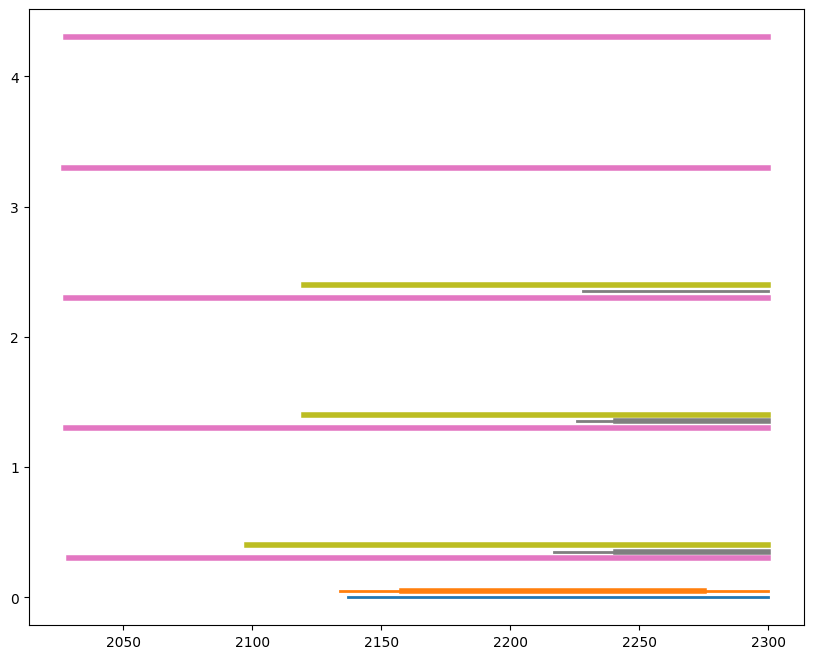

In [117]:
fig,ax=plt.subplots(figsize=(10,8))
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
labs=df_TEs.index.values
years = np.arange(1850,2301)
counter=0
for scen,s in enumerate(scenarios):
    temp = df[s].to_numpy()
    if (not PA_compliant(moving_avg(temp)) ) & OS_ref(temp):
        for i in range(9):
            zeros = data[scen,i,:] == 0
            ones = data[scen,i,:] == 1
            # plt.scatter()
            # plt.plot()
            plt.plot(years[~ones&~zeros], np.zeros_like(years)[~ones&~zeros]+i/20+counter,color=colors[i],lw=2)
            plt.plot(years[ones], np.zeros_like(years)[ones]+i/20+counter,color=colors[i],lw=4)
        counter+=1
    
# plt.legend()

(2000.0, 2300.0)

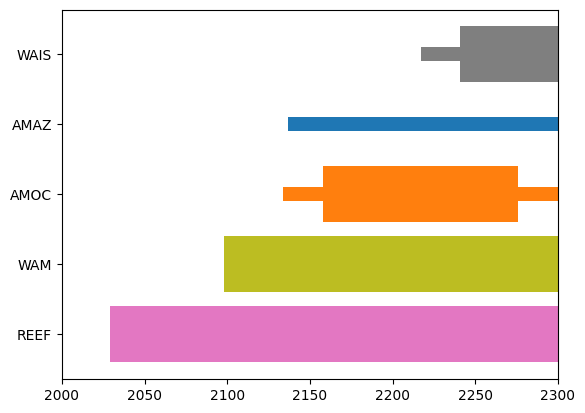

In [233]:
scen=1
years = np.arange(1850,2301)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = np.array(prop_cycle.by_key()['color'])
one_yrs = [years[data[scen,i,:]==1] for i in range(9)]
mid_yrs = [years[data[scen,i,:]>0] for i in range(9)]
inc = np.array([len(y)>0 for y in mid_yrs])

# order = (data[scen,:,:]>0.1).argmax(axis=1).argsort()
order=np.argsort([len(y) for y in mid_yrs])[::-1]
lefts=np.array([1850]*9)
for i in range(9):
    if len(mid_yrs[i])>0:
        lefts[i] = min(mid_yrs[i])

plt.barh(df_TEs.index.values[order][inc[order]], 
         np.array([len(mid_yrs[i]) for i in range(9)])[order][inc[order]], 
         left=lefts[order][inc[order]],height=0.2,color=colors[order][inc[order]])

lefts = np.array([1850]*9)
for i in range(9):
    if len(one_yrs[i])>0:
        lefts[i] = min(one_yrs[i])
# max_yrs = np.array([one_yrs[i].max() for i in range(9) if len(one_yrs[i]) > 0])
plt.barh(df_TEs.index.values[order][inc[order]],np.array([len(one_yrs[i]) for i in range(9)])[order][inc[order]],
         left=lefts[order][inc[order]],color=colors[order][inc[order]])

plt.xlim(2000,2300)

In [223]:
np.where(scenarios == 'ModAct_SAP')[0][0]

np.int64(4)

In [189]:
print(inc)

[True, True, False, False, False, False, True, True, True]


In [224]:
np.array([[1850]*9]*2).shape

(2, 9)

In [231]:
data = (D>0.1).mean(axis=1)
data.shape

(15, 9, 451)

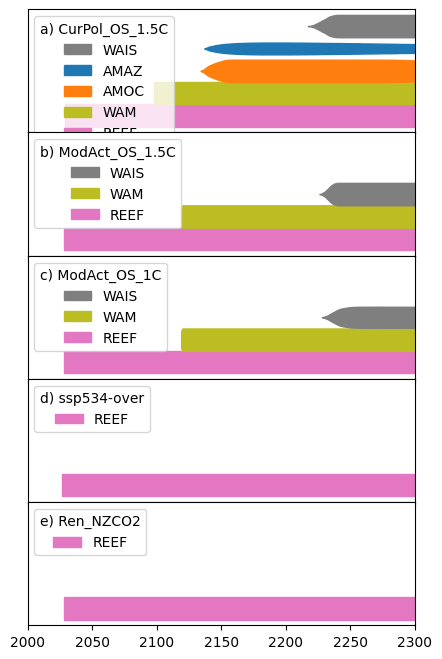

In [316]:
worse_scenarios = []
for s in scenarios:
    temp = df[s].to_numpy()
    if (not PA_compliant(moving_avg(temp)) ) & (OS_ref(temp)):
        worse_scenarios += [s]

data = (D>0.1).mean(axis=1)#D.mean(axis=1)
fig,axs=plt.subplots(figsize=(5,8),nrows=len(worse_scenarios),sharex=True,sharey=True)
fig.subplots_adjust(hspace=0,wspace=0)
axs[0].set_xlim(2000,2300)
axs[0].set_yticks([])
axs[2].set_xlabel('Year')
letters='abcdefghijk'
for i_ax,s in enumerate(worse_scenarios):
    i = np.where(scenarios==s)[0][0]
    # axs[i_ax].annotate(letters[i_ax]+') '+s,(0.04,0.95),xycoords='axes fraction',fontsize=12,ha='left',va='top')
    order = np.argsort(data[i,:,:].sum(axis=1))[::-1]
    for j in range(9):
        if data[i,order[j],:].sum() > 0:
            start = np.argmax(data[i,order[j],:] > 0)
            axs[i_ax].fill_between(years[start:],
                                   j-(data[i,order[j],start:])/2,
                                   j+(data[i,order[j],start:])/2, color=colors[order][j],label=df_TEs.index.values[order][j])
    handles, labels = axs[i_ax].get_legend_handles_labels()
    axs[i_ax].legend(handles[::-1],labels[::-1],title=letters[i_ax]+') '+s,loc='upper left')
        # start=0
        # axs[i_ax].fill_between(years[start:],
        #                        j-(1-data[i,order[j],start:])/2,
        #                        j+(1-data[i,order[j],start:])/2, color=colors[order][j])

In [322]:
for i in range(6):
    print(i//2)

0
0
1
1
2
2


/tmp/ipykernel_90909/1678578309.py:30: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/tmp/ipykernel_90909/1678578309.py:30: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



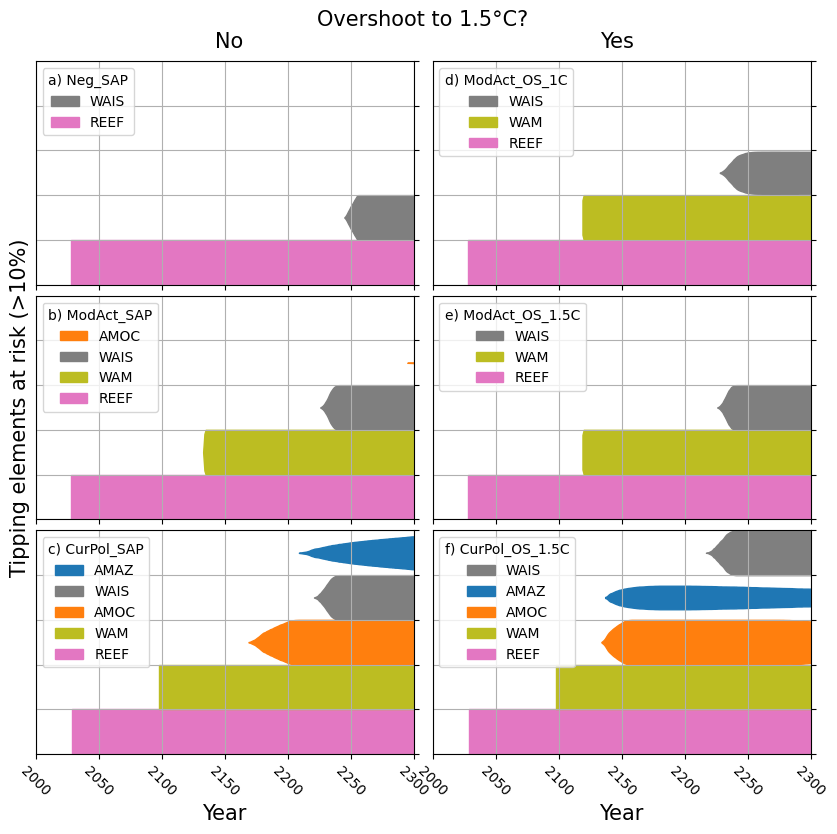

In [353]:
data = (D>0.1).mean(axis=1)#D.mean(axis=1)

fig,axs=plt.subplots(figsize=(10,9),nrows=3, ncols=2,sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05,wspace=0.05)
plot_scenarios = ['Neg_SAP', 'ModAct_SAP', 'CurPol_SAP', 
                  'ModAct_OS_1C', 'ModAct_OS_1.5C', 'CurPol_OS_1.5C']
letters ='abcdef'
axs[0,0].set_xlim(2000,2300)
axs[0,0].set_ylim(-0.5,4.5)
# axs[0,0].set_yticks
axs[0,0].set_yticks(np.arange(-.5,5,step=1),labels=['']*6)
for i_ax,s in enumerate(plot_scenarios):
    # axs[i_ax%3,i_ax//3].annotate(letters[i_ax] +') ' + s,(0.04,0.95), 
    #                        xycoords='axes fraction', ha='left',va='top',fontsize=12)
    i = np.where(scenarios==s)[0][0]
    # axs[i_ax].annotate(letters[i_ax]+') '+s,(0.04,0.95),xycoords='axes fraction',fontsize=12,ha='left',va='top')
    order = np.argsort(data[i,:,:].sum(axis=1))[::-1]
    for j in range(9):
        if data[i,order[j],:].sum() > 0:
            start = np.argmax(data[i,order[j],:] > 0)
            axs[i_ax%3,i_ax//3].fill_between(years[start:],
                                   j-(data[i,order[j],start:])/2,
                                   j+(data[i,order[j],start:])/2, color=colors[order][j],label=df_TEs.index.values[order][j])
    handles, labels = axs[i_ax%3,i_ax//3].get_legend_handles_labels()
    axs[i_ax%3,i_ax//3].legend(handles[::-1],labels[::-1],title=letters[i_ax]+') '+s,loc='upper left')
    axs[i_ax%3,i_ax//3].yaxis.tick_right()
    axs[i_ax%3,i_ax//3].grid()

for i in range(2):
    axs[2,i].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='top')
    axs[2,i].set_xlabel('Year',fontsize=15)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=False)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center',fontsize=15)
# ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
# ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Tipping elements at risk (>10%)',fontsize=15)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
# ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")
fig.savefig('../../Figures/Overshoots/PROVIDE/AM22_PA_incomp.pdf',bbox_inches='tight')

In [315]:
axs.shape

(3,)

In [270]:
start

np.int64(0)

In [259]:
data[0,:,:].sum(axis=1)

array([ 41.262, 115.54 ,   0.   ,   0.   ,   0.   ,   0.   , 272.   ,
        70.418, 203.   ])

In [257]:
order

array([0, 1, 2, 3, 4, 5, 7, 8, 6])

In [219]:
print(worse_scenarios)

['CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C', 'ssp534-over', 'Ren_NZCO2']


# Simulations with GTPR25 thresholds

In [4]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [5]:
# -------- SIMULATIONS --------------
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df[s].to_numpy()[t], T_lim, betas))

In [6]:
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in tqdm.tqdm(range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

100%|██████████████████████████████████████| 450/450 [00:00<00:00, 10257.36it/s]


/tmp/ipykernel_28887/1503327616.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_28887/1503327616.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


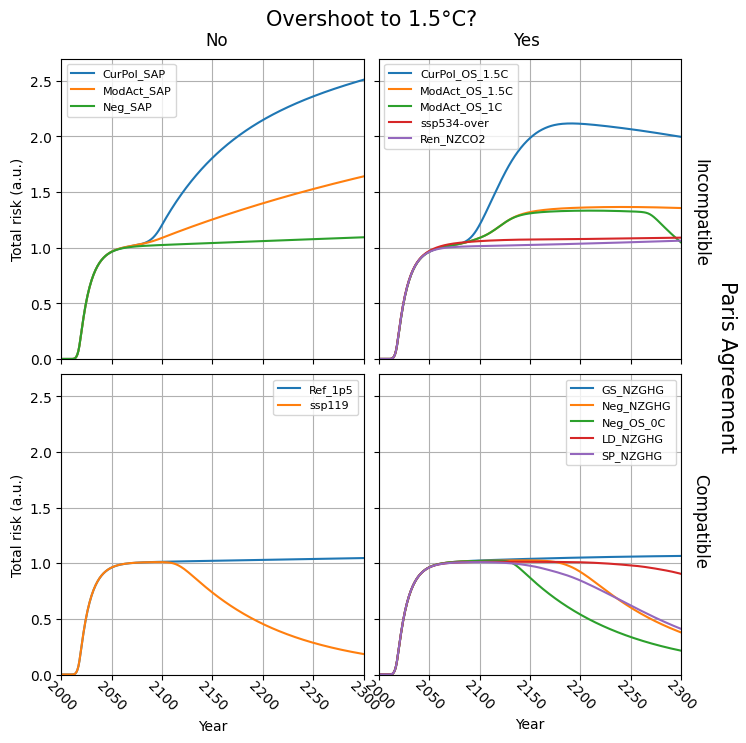

In [7]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
axs[0,0].set_ylim(0,2.7)
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        D[i,:,:,:].mean(axis=0).sum(axis=0), label=s)
    # util.plot.ribbon_plot(axs[int(PA_compliant(moving_avg(temp))), 
    #     int(OS_ref(temp,ref=1.5))], 
    #                       years, D[i,:,:,:].sum(axis=1), axis=0, color='red',shade=[1],alpha=[0.3],label=[''])
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Total risk (a.u.)')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")

path_out = '../../Figures/Overshoots/PROVIDE/total_risk_GTPR2025.png'
fig.savefig(path_out,bbox_inches='tight')

(2100.0, 2300.0)

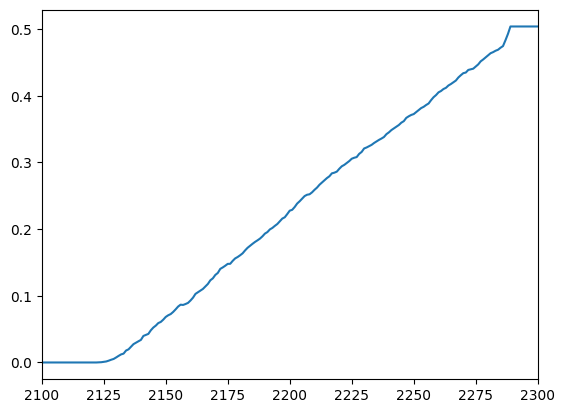

In [368]:
plt.plot(years,df['ModAct_OS_1.5C'].to_numpy() - df['ModAct_OS_1C'].to_numpy())
plt.xlim(2100,2300)

In [ ]:
TEs=df_TEs.index.values
print(TEs)

In [ ]:
np.where(TEs=='AMAZ')[0][0]

/tmp/ipykernel_28887/483391873.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_28887/483391873.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


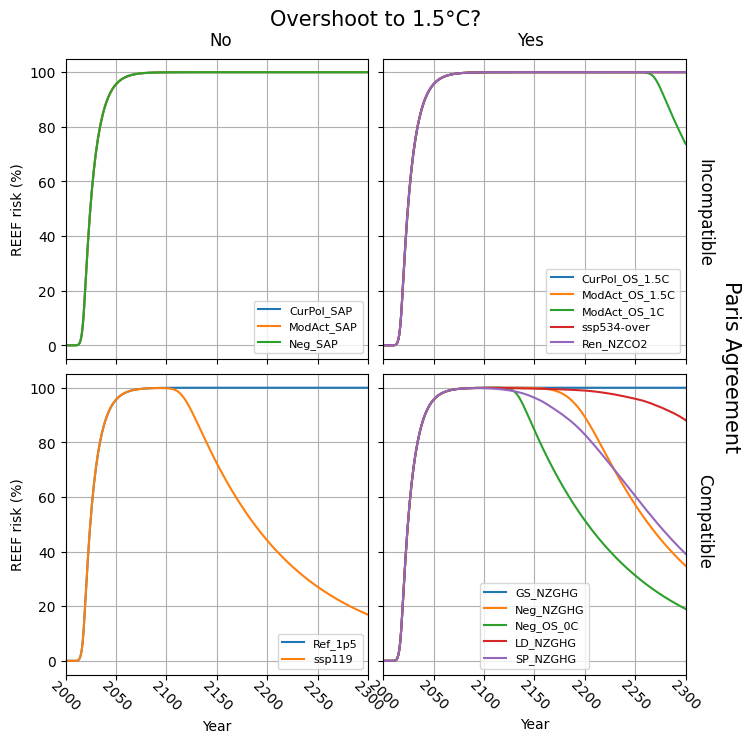

In [9]:
TE= 'REEF'
te_ind = np.where(df_TEs.index.values==TE)[0][0]
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,3.5)
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        D[i,:,te_ind,:].mean(axis=0)*100, label=s)
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel(TE+' risk (%)')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")

path_out = '../../Figures/Overshoots/PROVIDE/%s_risk_GTPR2025.png'%TE
fig.savefig(path_out,bbox_inches='tight')

/tmp/ipykernel_98833/762252096.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_98833/762252096.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


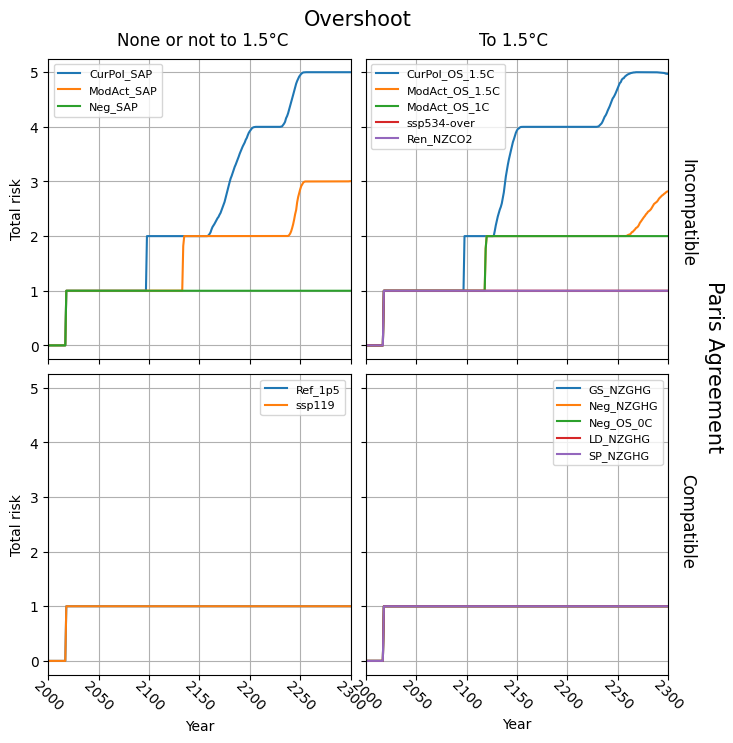

In [23]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=True)
plt.subplots_adjust(wspace=0.05,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,3.5)
data = (D>0.1).mean(axis=1).sum(axis=1)
# j=7
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        data[i,:], label=s)
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=8)
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Total risk')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['None or not to 1.5°C', 'To 1.5°C'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")

In [22]:
worse_scenarios2

['CurPol_SAP', 'ModAct_SAP', 'Neg_SAP']

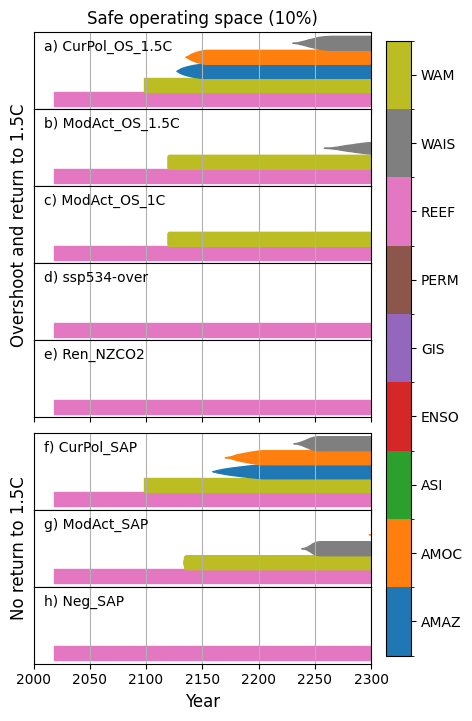

In [72]:
worse_scenarios1 = []
worse_scenarios2 = []
for s in scenarios:
    temp = df[s].to_numpy()
    if (not PA_compliant(moving_avg(temp)) ): 
        if (OS_ref(temp)):
            worse_scenarios1 += [s]
        else:
            worse_scenarios2 += [s]


# for s in scenarios:
#     temp = df[s].to_numpy()
#     if (not PA_compliant(moving_avg(temp)) ) & (not OS_ref(temp)):
#         worse_scenarios2 += [s]

space_size=0.2
data = (D>0.1).mean(axis=1)#D.mean(axis=1)
gridspec = dict(hspace=0.0, height_ratios=[1]*5+[space_size]+[1]*3)
fig,axs=plt.subplots(figsize=(5,
                              len(worse_scenarios1)+len(worse_scenarios2)+space_size),
                     nrows=len(worse_scenarios1)+len(worse_scenarios2)+1,
                     sharex=True,sharey=True,gridspec_kw=gridspec)
fig.subplots_adjust(hspace=0,wspace=0)
axs[0].set_xlim(2000,2300)
axs[0].set_yticks([])
axs[-1].set_xlabel('Year',fontsize=12)
letters='abcdefghijk'

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = np.array(prop_cycle.by_key()['color'])
cmap = mpl.colors.ListedColormap(colors[:-1])
bounds = np.arange(len(df_TEs)+1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

k=0
for ws in [worse_scenarios1,worse_scenarios2]:
    for i_ax,s in enumerate(ws):
        i = np.where(scenarios==s)[0][0]
        # axs[i_ax].annotate(letters[i_ax]+') '+s,(0.04,0.95),xycoords='axes fraction',fontsize=12,ha='left',va='top')
        order = np.argsort(data[i,:,:].sum(axis=1))[::-1]
        for j in range(9):
            if data[i,order[j],:].sum() > 0:
                start = np.argmax(data[i,order[j],:] > 0)
                axs[i_ax+k].fill_between(years[start:],
                                       j-(data[i,order[j],start:])/2,
                                       j+(data[i,order[j],start:])/2, color=colors[:-1][order][j],label=df_TEs.index.values[order][j])
        
        # handles, labels = axs[i_ax].get_legend_handles_labels()
        # axs[i_ax].legend(handles[::-1],labels[::-1],title=letters[i_ax]+') '+s,loc='upper left')
        axs[i_ax+k].grid(axis='x')
        axs[i_ax+k].annotate(letters[i_ax+max(0,k-1)]+') '+s, (0.03,0.9), xycoords='axes fraction',va='top')
            # start=0
            # axs[i_ax].fill_between(years[start:],
            #                        j-(1-data[i,order[j],start:])/2,
            #                        j+(1-data[i,order[j],start:])/2, color=colors[order][j])
    k+=len(ws)+1
axs[len(worse_scenarios1)].set_visible(False)
# axs[len(worse_scenarios1)].set_xticks(np.arange(2000,2350,step=50),labels=np.arange(2000,2350,step=50))
fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.83, 0.12, 0.05, 0.75])
cbar=fig.colorbar(
    mpl.cm.ScalarMappable(cmap=cmap, norm=norm),
    cax=cbar_ax,
    spacing='proportional',ticks=np.arange(0.5,9.5,step=1))
cbar.set_ticklabels(df_TEs.index.values)
axs[0].set_title('Safe operating space (10%)')
axs[-2].set_ylabel('No return to 1.5C',fontsize=12)
axs[2].set_ylabel('Overshoot and return to 1.5C',fontsize=12)
# fig.colorbar(im, cax=cbar_ax)

path_out = '../../Figures/Overshoots/PROVIDE/notPA_SOS_GTPR2025.png'
fig.savefig(path_out,bbox_inches='tight')

In [45]:
colors

array(['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b',
       '#e377c2', '#7f7f7f', '#bcbd22', '#17becf'], dtype='<U7')

/tmp/ipykernel_98833/746834973.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[2,i].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='top')
/tmp/ipykernel_98833/746834973.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[2,i].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='top')


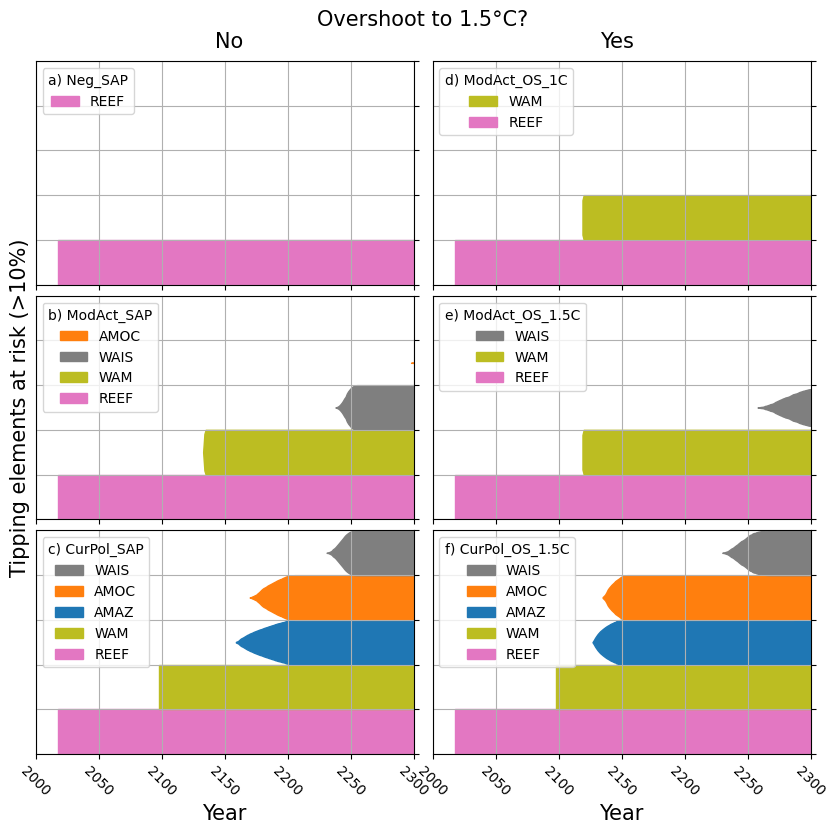

In [32]:
data = (D>0.1).mean(axis=1)#D.mean(axis=1)

fig,axs=plt.subplots(figsize=(10,9),nrows=3, ncols=2,sharex=True,sharey=True)
fig.subplots_adjust(hspace=0.05,wspace=0.05)
plot_scenarios = ['Neg_SAP', 'ModAct_SAP', 'CurPol_SAP', 
                  'ModAct_OS_1C', 'ModAct_OS_1.5C', 'CurPol_OS_1.5C']
letters ='abcdef'
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = np.array(prop_cycle.by_key()['color'])
axs[0,0].set_xlim(2000,2300)
axs[0,0].set_ylim(-0.5,4.5)
# axs[0,0].set_yticks
axs[0,0].set_yticks(np.arange(-.5,5,step=1),labels=['']*6)
for i_ax,s in enumerate(plot_scenarios):
    # axs[i_ax%3,i_ax//3].annotate(letters[i_ax] +') ' + s,(0.04,0.95), 
    #                        xycoords='axes fraction', ha='left',va='top',fontsize=12)
    i = np.where(scenarios==s)[0][0]
    # axs[i_ax].annotate(letters[i_ax]+') '+s,(0.04,0.95),xycoords='axes fraction',fontsize=12,ha='left',va='top')
    order = np.argsort(data[i,:,:].sum(axis=1))[::-1]
    for j in range(9):
        if data[i,order[j],:].sum() > 0:
            start = np.argmax(data[i,order[j],:] > 0)
            axs[i_ax%3,i_ax//3].fill_between(years[start:],
                                   j-(data[i,order[j],start:])/2,
                                   j+(data[i,order[j],start:])/2, color=colors[order][j],label=df_TEs.index.values[order][j])
    handles, labels = axs[i_ax%3,i_ax//3].get_legend_handles_labels()
    axs[i_ax%3,i_ax//3].legend(handles[::-1],labels[::-1],title=letters[i_ax]+') '+s,loc='upper left')
    axs[i_ax%3,i_ax//3].yaxis.tick_right()
    axs[i_ax%3,i_ax//3].grid()

for i in range(2):
    axs[2,i].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='top')
    axs[2,i].set_xlabel('Year',fontsize=15)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=False)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center',fontsize=15)
# ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
# ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Tipping elements at risk (>10%)',fontsize=15)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
# ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")
fig.savefig('../../Figures/Overshoots/PROVIDE/GTPR25_PA_incomp.pdf',bbox_inches='tight')